# Эволюционный поиск графа для GNN на MNIST

In [ ]:
%pip install tqdm matplotlib numpy pandas torch torchvision scikit-learn

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.collections import LineCollection
from torchvision.datasets import MNIST

from src.evolution import Evolution
from src.generation import generate_graphs
from src.gnn import DEVICE, accuracy, train_gnn

SEED = 14317
IMAGE_SIDE = 28
VERTEX_COUNT = IMAGE_SIDE * IMAGE_SIDE
GRAPH_COUNT = 160
GROUP_COUNT = 32
MIN_EDGES = 100
MAX_EDGES = VERTEX_COUNT * (VERTEX_COUNT - 1) // 4
MUTATION_RATE = 10 / VERTEX_COUNT
GENERATION_COUNT = 10
FITNESS_EPOCHS = 3
FINAL_EPOCHS = 10
TRAIN_SIZE = 5_000
TEST_SIZE = 1_000
RESULTS_DIR = Path("results")
GRAPHS_DIR = RESULTS_DIR / "best_graphs"

print("Device:", DEVICE)

Device: cpu


## Данные

In [2]:
train_dataset = MNIST(root="data", train=True, download=True)
test_dataset = MNIST(root="data", train=False, download=True)
train_images = train_dataset.data.reshape(-1, VERTEX_COUNT).to(torch.float32) / 255
train_labels = train_dataset.targets
test_images = test_dataset.data.reshape(-1, VERTEX_COUNT).to(torch.float32) / 255
test_labels = test_dataset.targets


## Функции

In [3]:
def fitness(graph, train_images, train_labels, test_images, test_labels):
    adjacency = graph.astype(np.float32)
    model = train_gnn(adjacency, train_images, train_labels, FITNESS_EPOCHS)
    return accuracy(model, adjacency, test_images, test_labels)


def describe(prefix, values):
    statistics = pd.Series(values).describe().drop("count")
    return statistics.add_prefix(prefix + "_").to_dict()


def describe_generation(graphs, scores):
    edge_counts = graphs.sum(axis=(1, 2)) // 2
    row = {"best_accuracy": scores[0], "best_edges": edge_counts[0]}
    row |= describe("best_degree", graphs[0].sum(axis=1))
    row |= describe("accuracy", scores)
    row |= describe("edges", edge_counts)
    return row


pixel_rows, pixel_columns = np.divmod(np.arange(VERTEX_COUNT), IMAGE_SIDE)
PIXEL_COORDINATES = np.stack([pixel_columns, IMAGE_SIDE - 1 - pixel_rows], axis=1)


def draw_graph(graph, title):
    starts, ends = np.nonzero(np.triu(graph))
    segments = np.stack([PIXEL_COORDINATES[starts], PIXEL_COORDINATES[ends]], axis=1)
    has_edges = graph.any(axis=1)
    connected = PIXEL_COORDINATES[has_edges]
    isolated = PIXEL_COORDINATES[~has_edges]
    figure, axis = plt.subplots(figsize=(6, 6))
    axis.add_collection(LineCollection(segments, colors="#c62828", linewidths=0.5, alpha=0.5))
    axis.scatter(isolated[:, 0], isolated[:, 1], s=7, c="#1976d2")
    axis.scatter(connected[:, 0], connected[:, 1], s=7, c="#f28e2b")
    axis.set_aspect("equal")
    axis.axis("off")
    axis.set_title(title)
    plt.show()


def log_generation(generation):
    graphs = evolution.get_graphs()
    scores = evolution.get_scores()
    best_graphs.append(graphs[0].copy())
    history.append(describe_generation(graphs, scores))

    pd.DataFrame(history).to_csv(RESULTS_DIR / "history.csv", index_label="generation")
    np.save(GRAPHS_DIR / f"generation_{generation:03d}.npy", graphs[0])

In [4]:
def has_nonzero_diagonal(matrix):
    """Return True if any diagonal element is nonzero."""
    return bool(np.any(np.diag(matrix) != 0))


## Начальная популяция

In [5]:
group_edge_counts = np.geomspace(MIN_EDGES, MAX_EDGES, GROUP_COUNT).round().astype(int)
edge_counts = np.repeat(group_edge_counts, GRAPH_COUNT // GROUP_COUNT)
rng = np.random.default_rng(SEED)
graphs = generate_graphs(GRAPH_COUNT, edge_counts, VERTEX_COUNT, rng)

## Эволюция

In [6]:
from tqdm import trange

In [7]:
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
history = []
best_graphs = []

evolution = Evolution(
    graphs,
    fitness,
    MUTATION_RATE,
    seed=SEED,
    images=train_images,
    labels=train_labels,
    train_size=TRAIN_SIZE,
    test_size=TEST_SIZE,
)
log_generation(0)
for generation in trange(1, GENERATION_COUNT):
    evolution.evolve()
    log_generation(generation)

history = pd.DataFrame(history)
history

100%|██████████| 9/9 [00:40<00:00,  4.47s/it]


,best_accuracy,best_edges,best_degree_mean,best_degree_std,best_degree_min,best_degree_25%,best_degree_50%,best_degree_75%,best_degree_max,accuracy_mean,...,accuracy_50%,accuracy_75%,accuracy_max,edges_mean,edges_std,edges_min,edges_25%,edges_50%,edges_75%,edges_max
0,0.840,841,2.145408,1.426543,0.0,1.0,2.0,3.0,7.0,0.454000,...,0.4905,0.77225,0.840,22746.68750,37995.064882,100.0,629.0,3945.0,24653.75,153468.0
1,0.853,841,2.145408,1.421161,0.0,1.0,2.0,3.0,8.0,0.554700,...,0.5085,0.79300,0.853,2976.01250,2149.655602,100.0,629.0,3956.5,4706.75,6708.0
2,0.838,841,2.145408,1.421161,0.0,1.0,2.0,3.0,8.0,0.556369,...,0.4970,0.78400,0.838,3024.83125,2206.814116,100.0,629.0,4103.0,4769.75,7281.0
3,0.863,841,2.145408,1.482733,0.0,1.0,2.0,3.0,10.0,0.555188,...,0.5015,0.80450,0.863,3049.99375,2240.627149,100.0,629.0,4114.0,4741.00,7383.0
4,0.850,664,1.693878,1.336457,0.0,1.0,1.5,2.0,7.0,0.564975,...,0.5465,0.79625,0.850,3014.96250,2189.594939,100.0,629.0,4076.0,4704.00,7222.0
5,0.847,664,1.693878,1.318176,0.0,1.0,1.0,2.0,7.0,0.567138,...,0.5550,0.78575,0.847,3029.46250,2193.888810,100.0,629.0,4090.0,4770.75,6904.0
6,0.850,664,1.693878,1.279832,0.0,1.0,2.0,2.0,6.0,0.559194,...,0.5365,0.78700,0.850,3028.31250,2206.084046,100.0,629.0,4118.5,4580.00,7188.0
7,0.856,841,2.145408,1.479284,0.0,1.0,2.0,3.0,8.0,0.542606,...,0.4975,0.80025,0.856,3111.47500,2268.388525,100.0,629.0,4169.5,4883.50,7367.0
8,0.855,1066,2.719388,1.617381,0.0,2.0,3.0,4.0,8.0,0.568094,...,0.5055,0.78750,0.855,2984.00625,2151.040352,100.0,629.0,4090.0,4638.00,7090.0
9,0.862,1066,2.719388,1.617381,0.0,2.0,3.0,4.0,8.0,0.553650,...,0.5195,0.79075,0.862,3129.33125,2304.712148,100.0,629.0,4150.0,4994.75,8091.0


## Лучшие графы

In [8]:
import ipywidgets as widgets
from IPython.display import display


def show_best_graph(generation, with_grid8_mask: bool = False):
    index = generation - 1
    row = history.loc[index]
    graph = best_graphs[index]
    edge_count = int(row['best_edges'])
    if with_grid8_mask:
        distances = np.abs(PIXEL_COORDINATES[:, None, :] - PIXEL_COORDINATES[None, :, :])
        grid8_mask = distances.max(axis=-1) == 1
        graph = np.where(grid8_mask, graph, 0)
        edge_count = np.count_nonzero(np.triu(graph, k=1))
    draw_graph(
        graph,
        f"Поколение {generation}: accuracy {row['best_accuracy']:.4f}, рёбер {edge_count}",
    )


best_graph_widget = widgets.interactive(
    show_best_graph,
    generation=widgets.IntSlider(
        value=1,
        min=1,
        max=len(best_graphs),
        step=1,
        description="Поколение:",
        continuous_update=False,
        style={"description_width": "initial"},
    ),
    with_grid8_mask=widgets.Checkbox(value=False, description="Только grid-8"),
)
display(best_graph_widget)


interactive(children=(IntSlider(value=1, continuous_update=False, description='Поколение:', max=10, min=1, sty…

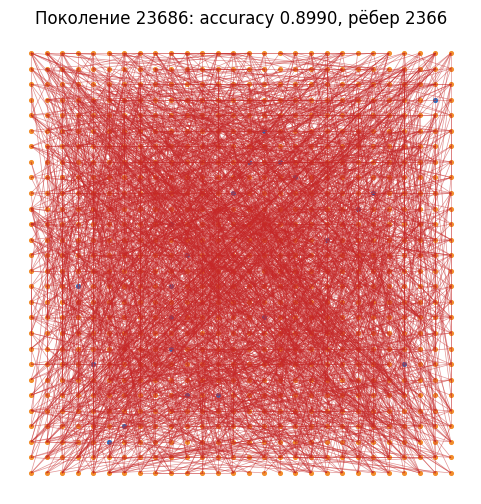

In [33]:
show_best_graph(len(history))

## Динамика метрик

In [10]:
def plot_metrics(columns, skip_first=0):
    plot_history = history.iloc[skip_first:]
    row_count = math.ceil(len(columns) / 3)
    figure, axes = plt.subplots(row_count, 3, figsize=(15, 3.5 * row_count), squeeze=False)
    for axis, column in zip(axes.flat, columns):
        axis.plot(plot_history.index, plot_history[column], marker=".")
        axis.set_title(column)
        axis.set_xlabel("Поколение")
    for axis in axes.flat[len(columns):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

### Лучшая модель

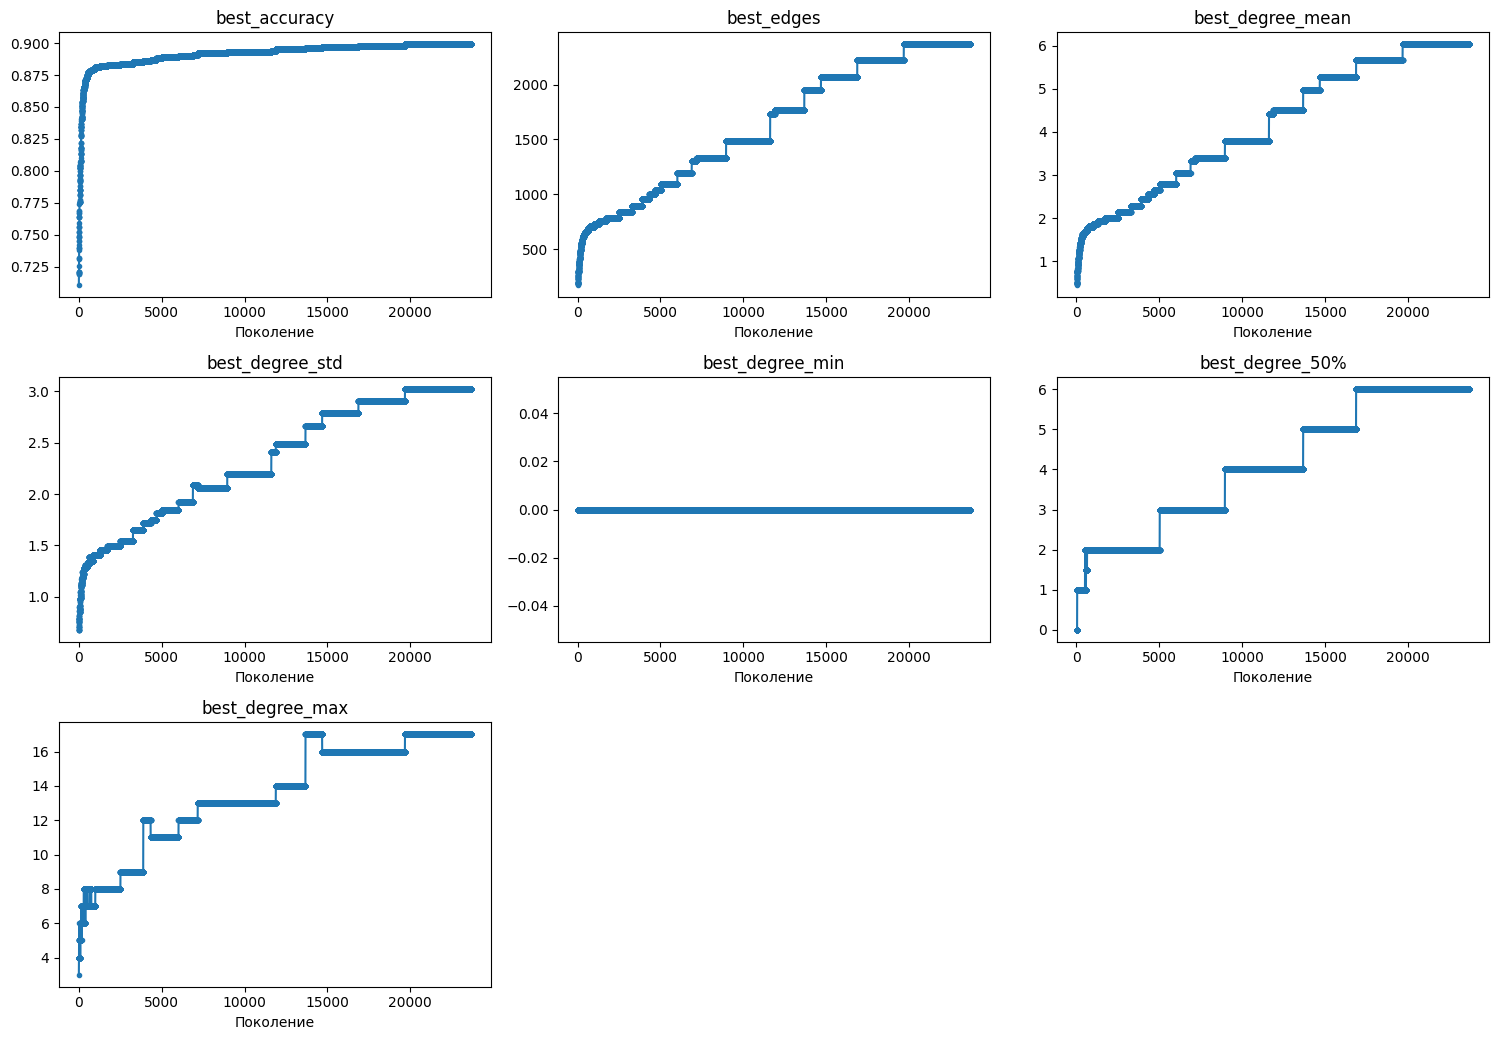

In [11]:
plot_metrics([
    "best_accuracy",
    "best_edges",
    "best_degree_mean",
    "best_degree_std",
    "best_degree_min",
    "best_degree_50%",
    "best_degree_max",
], skip_first=10)

### Число рёбер в популяции

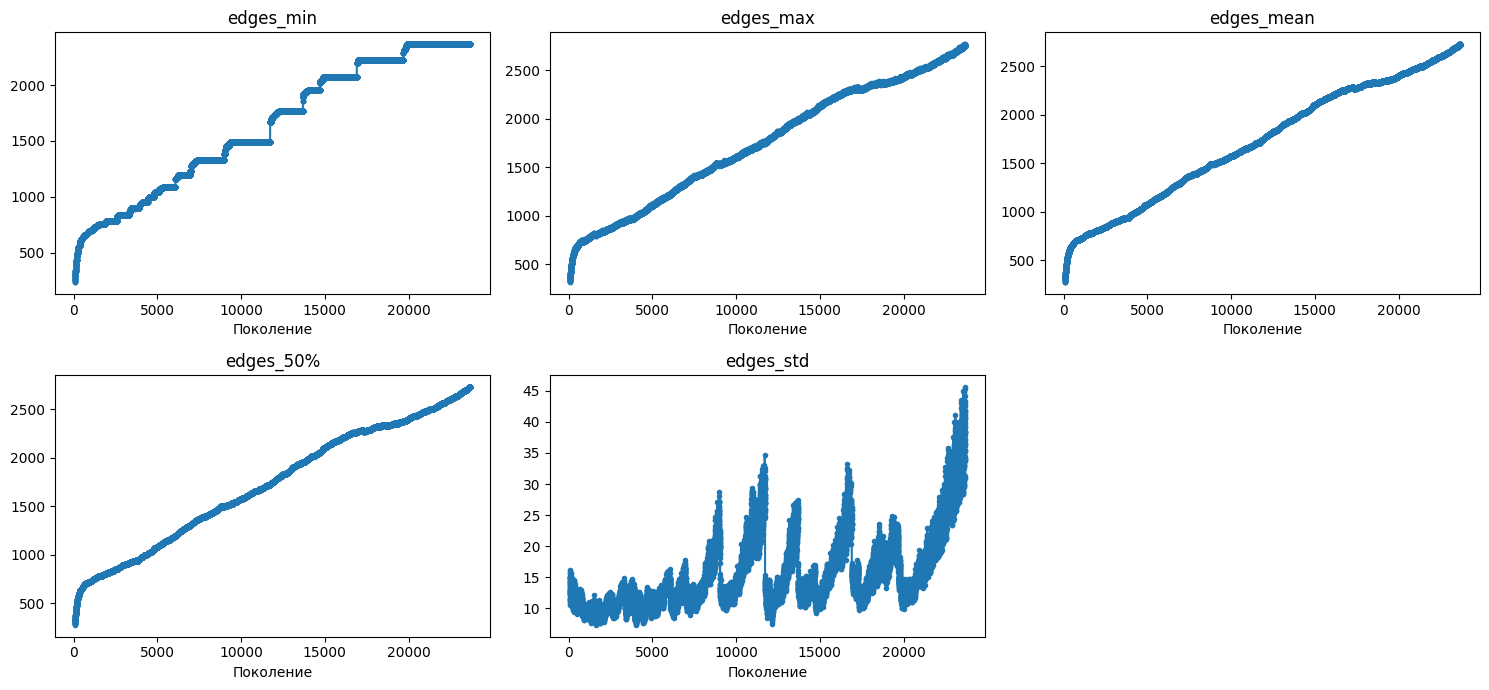

In [12]:
plot_metrics(["edges_min", "edges_max", "edges_mean", "edges_50%", "edges_std"], skip_first=50)

### Accuracy в популяции

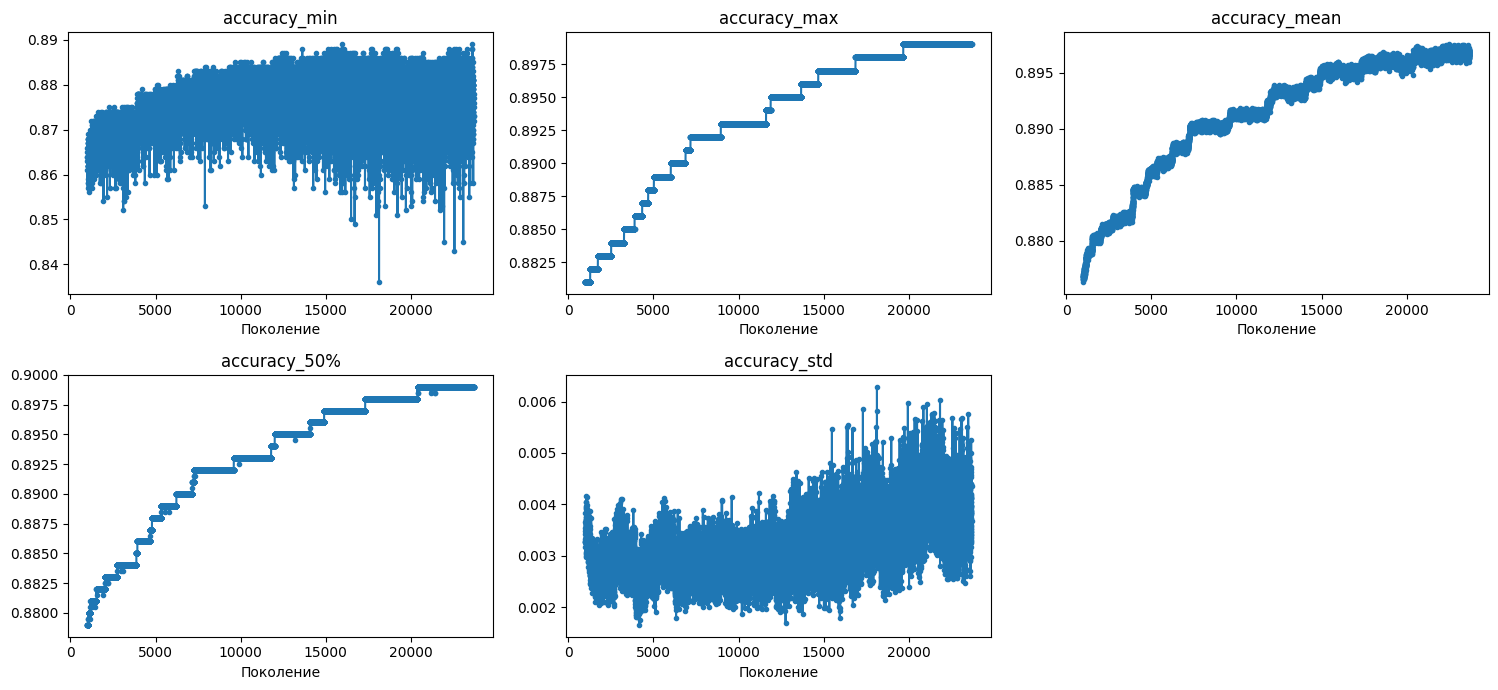

In [13]:
plot_metrics(["accuracy_min", "accuracy_max", "accuracy_mean", "accuracy_50%", "accuracy_std"], skip_first=1000)

## GNN на лучшем графе

In [14]:
def get_history(adjacency):
    history = []
    for num_epochs in trange(1, 1000, FINAL_EPOCHS):
        model = train_gnn(adjacency, train_images, train_labels, num_epochs)
        history.append(accuracy(model, adjacency, test_images, test_labels))
    return history

In [25]:
best_adjacency = best_graphs[-1].astype(np.float32)
final_model = train_gnn(best_adjacency, train_images, train_labels, FINAL_EPOCHS * 100)
print("Test accuracy:", accuracy(final_model, best_adjacency, test_images, test_labels))

Test accuracy: 0.97


In [ ]:
worst_adjacency = evolution.get_graphs()[-1].astype(np.float32)
final_model = train_gnn(worst_adjacency, train_images, train_labels, FINAL_EPOCHS)
print("Test accuracy:", accuracy(final_model, worst_adjacency, test_images, test_labels))

In [ ]:
initial_best_adj = best_graphs[0].copy()
final_best_adj = best_graphs[-1].copy()
final_worst_adj = evolution.get_graphs()[-1].copy()

initial_best_history = get_history(initial_best_adj)
final_best_history = get_history(final_best_adj)
final_worst_history = get_history(final_worst_adj)

100%|██████████| 100/100 [01:05<00:00,  1.52it/s]


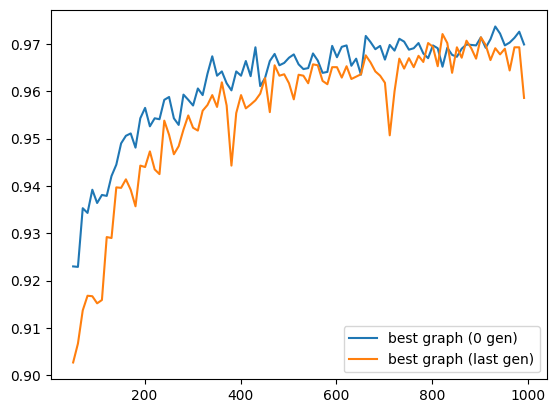

In [ ]:
import matplotlib.pyplot as plt
points = list(range(1, 1000, FINAL_EPOCHS))

SKIP_FIRST = 5
plt.plot(points[SKIP_FIRST:], initial_best_history[SKIP_FIRST:], label='best graph (0 gen)')
plt.plot(points[SKIP_FIRST:], final_best_history[SKIP_FIRST:], label='best graph (last gen)')
plt.plot(points[SKIP_FIRST:], final_worst_history[SKIP_FIRST:], label='worst graph (last gen)')
plt.legend()
plt.show()

In [ ]:
print(initial_best_history[-1], final_best_history[-1], final_worst_history[-1])

0.9699 0.9586
